# Customer Churn Prediction & Retention Intelligence

## 1. Objective

The objective of this project is to develop an end-to-end machine learning system
that identifies customers who are at a high risk of churning.

The system will use historical customer information to:

- Understand customer characteristics and churn patterns.
- Identify factors associated with customer churn.
- Estimate the probability of churn for individual customers.
- Rank customers according to their predicted churn risk.
- Support retention teams in prioritizing customers for potential intervention.

The project will focus on building a reliable and reproducible machine learning
pipeline, with particular attention to data quality, leakage prevention,
model evaluation, and practical business applicability.

## 2. Dataset

The project uses the IBM Telco Customer Churn dataset.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import sys

#### Locate and Load the dataset

In [2]:
# Add the project root to Python's module search path
PROJECT_ROOT = Path.cwd().parent

sys.path.append(str(PROJECT_ROOT))

# Import the reusable data loader
from src.data.load_data import load_data

In [3]:
# Define the dataset path
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Telco_customer_churn.xlsx"

# Load the dataset
df = load_data(DATA_PATH, sheet_name="Telco_Churn")

df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7891-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


#### Inspect the dataset dimensions

In [4]:
print(df.shape)
print(f"Number of Observations: {df.shape[0]}")
print(f"Number of features: {df.shape[1]}")

(7043, 33)
Number of Observations: 7043
Number of features: 33


In [5]:
for index, column in enumerate(df.columns, start=1):
    print(f"{index}. {column}")

1. CustomerID
2. Count
3. Country
4. State
5. City
6. Zip Code
7. Lat Long
8. Latitude
9. Longitude
10. Gender
11. Senior Citizen
12. Partner
13. Dependents
14. Tenure Months
15. Phone Service
16. Multiple Lines
17. Internet Service
18. Online Security
19. Online Backup
20. Device Protection
21. Tech Support
22. Streaming TV
23. Streaming Movies
24. Contract
25. Paperless Billing
26. Payment Method
27. Monthly Charges
28. Total Charges
29. Churn Label
30. Churn Value
31. Churn Score
32. CLTV
33. Churn Reason


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

#### Check missing values

In [7]:
# Calculate missing values for each column
missing_values = df.isnull().sum()

# Calculate missing-value percentages
missing_percentage = (missing_values/len(df))*100

# Combine the results
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage}
)

# Display only columns containing missing values
missing_summary[missing_summary["Missing Values"] > 0]

,Missing Values,Missing Percentage
Churn Reason,5174,73.463013


Only one column contains null values. However, we should not immediately conclude that 73.46% of this column's data is defective.

Let's investigate why these values are missing.

My hypothesis is that Churn Reason is populated only for customers who have churned. Let's test the hypothesis.

In [8]:
# Compare churn status with missingness in Churn Reason

df.groupby("Churn Label")["Churn Reason"].apply(
    lambda x: x.isnull().sum()
)

Churn Label
No     5174
Yes       0
Name: Churn Reason, dtype: int64

In [9]:
# Count records in each churn category
df["Churn Label"].value_counts()

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

Every customer who has not churned has a missing Churn Reason, while every customer who has churned has a recorded reason.

`Hypothesis confirmed`

This is an example of structural missingness. The values are missing because the information is not applicable to those customers, rather than because the information was accidentally lost.

#### Observation: Missing Values in Churn Reason

The dataset contains 5,174 missing values (73.46%) in the `Churn Reason`
column.

Investigation reveals that all 5,174 non-churned customers have missing
values, whereas all 1,869 churned customers have recorded churn reasons.

Therefore, the missingness is structural rather than an indication of
incomplete data.

The `Churn Reason` column will be excluded from predictive model inputs
because it contains information available only after the churn event.
However, it may be retained for retrospective business analysis.

#### Check duplicate records

In [10]:
# Gives out number of rows that are entirely same
print(f"Duplicate Observations: {df.duplicated().sum()}")

# Gives out number of duplicate customer IDs
print(f"Duplicate Customer IDs: {df['CustomerID'].duplicated().sum()}")

Duplicate Observations: 0
Duplicate Customer IDs: 0


* Count completely duplicated rows. For example, an observation is in 4 different rows and another observation is in 3 different places. The output would be 3+2 = 5. `df.duplicated().sum()`

* Count duplicate CustomerIDs. For example, an ID is in 4 different rows and another ID is in 3 different places. The output would be 3+2 = 5. `df["CustomerID"].duplicated().sum()`

* Count all records belonging to duplicate CustomerID groups. For example, an ID is in 4 different rows and another ID is in 3 different places. The output would be 4+3 = 7. `df["CustomerID"].duplicated(keep=False).sum()`

* Check duplicates based on selected columns. `df.duplicated(subset=["CustomerID", "Gender"]).sum()`

#### Observation: Duplicate Records

* No duplicate rows were identified in the dataset.
* No duplicate Customer IDs were found.
* Each record represents a unique customer, and there are no repeated customer identifiers.

#### Inspect numerical statistics

In [11]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


### Observation: Descriptive Statistics

1. The dataset contains 7,043 observations.
2. `Count` is constant across all records and has zero variance.
3. Customer tenure ranges from 0 to 72 months, with a mean of
   approximately 32.37 months.
4. Monthly charges range from $18.25 to $118.75, with a mean of
   approximately $64.76.
5. The mean of the binary `Churn Value` variable is 0.26537,
   indicating a churn proportion of approximately 26.54%.
6. `Churn Score` and `CLTV` require further investigation to establish
   their relevance and availability at prediction time.
7. ZIP codes, latitude and longitude represent geographic information
   and should not automatically be treated as ordinary numerical features.
8. `Total Charges` is absent from the numerical summary because it is
   currently stored as an object.

### Investigate Total Charges

In [12]:
# Inspect the first 20 unique values
df["Total Charges"].unique()[:20]

array([108.15, 151.65, 820.5, 3046.05, 5036.3, 528.35, 39.65, 20.15,
       4749.15, 30.2, 1093.1, 316.9, 3549.25, 1105.4, 144.15, 1426.4,
       633.3, 1752.55, 857.25, 79.35], dtype=object)

In [13]:
# Count blank strings
(df["Total Charges"].astype(str).str.strip() == "").sum()

np.int64(11)

The last two outputs tells us:
1. The first 20 unique values are numerical-looking values, stored as objects.
2. There are exactly 11 blank strings in Total Charges.
3. These blank strings are not actual Pandas NaN values. That's why df.info() reported 7,043 non-null values.  
  
This is an important distinction.

### Investigate the 11 affected customers

In [14]:
# Identify records with blank Total Charges
blank_charges = df[
    df["Total Charges"].astype(str).str.strip() == ""
]

# Inspect relevant columns
blank_charges[
    ["CustomerID", "Tenure Months", "Monthly Charges", "Total Charges", "Churn Label"]
]

,CustomerID,Tenure Months,Monthly Charges,Total Charges,Churn Label
2234,4472-LVYGI,0,52.55,,No
2438,3115-CZMZD,0,20.25,,No
2568,5709-LVOEQ,0,80.85,,No
2667,4367-NUYAO,0,25.75,,No
2856,1371-DWPAZ,0,56.05,,No
4331,7644-OMVMY,0,19.85,,No
4687,3213-VVOLG,0,25.35,,No
5104,2520-SGTTA,0,20.00,,No
5719,2923-ARZLG,0,19.70,,No
6772,4075-WKNIU,0,73.35,,No


### 1. What does this mean?
These customers have zero recorded tenure but already have an associated monthly subscription charge.

A plausible explanation is that they are newly registered customers who have not yet accumulated any total charges.

However, we should distinguish what we've observed from what we're inferring:
* Observed: All 11 customers have zero tenure and blank total charges.
* Likely explanation: They are newly registered customers without accumulated charges.
* Not established: Whether the blank values specifically mean zero billed charges or reflect a data-export convention.

### 2. How should we handle these values?

For this dataset, replacing the blank strings with zero is a reasonable interpretation to investigate, because total accumulated charges should plausibly be zero at zero tenure.

But let's preserve the original data and make the transformation explicit.

In [15]:
df_clean = df.copy()

In [16]:
'''
Why errors="coerce"? It tells Pandas that if a value cannot be converted into a number, replace it with NaN instead of raising an error.
- Valid numerical values are converted to numbers.
- Invalid values become NaN.
- The original df remains unchanged.
'''

df_clean["Total Charges"] = pd.to_numeric(
    df_clean["Total Charges"],
    errors="coerce"
)

# strip the space from the numeric values if there are any and then convert them into numeric datatype (float)

In [17]:
# .isna() checks each value and returns True if it is missing.
print("Missing values:", df_clean["Total Charges"].isna().sum()) 

print("Data type:", df_clean["Total Charges"].dtype)

Missing values: 11
Data type: float64


### Handle the 11 values

In [18]:
# It is a Boolean Mask
# A mask is simply a Series of True and False values used to identify particular rows.

mask = (
    df_clean["Total Charges"].isna()
    & (df_clean["Tenure Months"] == 0)
)

# df.loc[row_condition, column_name] = new_value
df_clean.loc[mask, "Total Charges"] = 0.0

In [19]:
print("Remaining missing values:", df_clean["Total Charges"].isna().sum())

Remaining missing values: 0


### Verify the cleaned dataset

In [20]:
# Inspect the cleaned dataset
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

### Review remaining object columns

In [21]:
# Display columns currently stored as object

# select_dtypes() is a Pandas DataFrame method used to select columns based on their data types.
# This returns a new DataFrame containing only the columns stored as object.

object_columns = df_clean.select_dtypes(include="object").columns

print("OBJECT COLUMNS:")
for column in object_columns:
    print(column)

# Display the number of object-type columns
print("Number of object columns:", len(object_columns))

OBJECT COLUMNS:
CustomerID
Country
State
City
Lat Long
Gender
Senior Citizen
Partner
Dependents
Phone Service
Multiple Lines
Internet Service
Online Security
Online Backup
Device Protection
Tech Support
Streaming TV
Streaming Movies
Contract
Paperless Billing
Payment Method
Churn Label
Churn Reason
Number of object columns: 23


### Inspect unique values in the object columns

In [22]:
for column in object_columns:
    print(f"{column}: {df_clean[column].nunique()} unique values")

CustomerID: 7043 unique values
Country: 1 unique values
State: 1 unique values
City: 1129 unique values
Lat Long: 1652 unique values
Gender: 2 unique values
Senior Citizen: 2 unique values
Partner: 2 unique values
Dependents: 2 unique values
Phone Service: 2 unique values
Multiple Lines: 3 unique values
Internet Service: 3 unique values
Online Security: 3 unique values
Online Backup: 3 unique values
Device Protection: 3 unique values
Tech Support: 3 unique values
Streaming TV: 3 unique values
Streaming Movies: 3 unique values
Contract: 3 unique values
Paperless Billing: 2 unique values
Payment Method: 4 unique values
Churn Label: 2 unique values
Churn Reason: 20 unique values


In [23]:
for column in object_columns:
    print(f"\n{column}")
    print(df_clean[column].value_counts(dropna=False))


CustomerID
CustomerID
3186-AJIEK    1
3668-QPYBK    1
9237-HQITU    1
7203-OYKCT    1
9837-FWLCH    1
             ..
1066-JKSGK    1
8779-QRDMV    1
4190-MFLUW    1
0280-XJGEX    1
7891-POOKP    1
Name: count, Length: 7043, dtype: int64

Country
Country
United States    7043
Name: count, dtype: int64

State
State
California    7043
Name: count, dtype: int64

City
City
Los Angeles      305
San Diego        150
San Jose         112
Sacramento       108
San Francisco    104
                ... 
Chester            4
Big Bar            4
Washington         4
Stonyford          4
Stirling City      4
Name: count, Length: 1129, dtype: int64

Lat Long
Lat Long
34.159534, -116.425984    5
33.28156, -115.955541     5
34.201108, -116.593456    5
33.798266, -118.300237    5
33.391181, -118.421305    5
                         ..
41.505916, -120.152505    4
41.764869, -122.671316    4
41.465121, -122.380947    4
40.021787, -122.127576    4
41.737962, -123.07557     4
Name: count, Length: 1652, dt

### Observation: Categorical Variables

1. CustomerID contains 7,043 unique values and serves as a customer identifier.
2. Country and State are constant across all observations.
3. City and Lat Long contain geographic information with relatively high cardinality.
4. Demographic variables contain binary categories.
5. Service-related variables contain categories such as Yes, No,
   No phone service, and No internet service.
6. Contract contains three categories: Month-to-month, One year,
   and Two year.
7. Payment Method contains four distinct categories.
8. Churn Label represents the binary target.
9. Churn Value is another representation of the same target and
   must not be included as a predictive input.
10. Churn Reason contains retrospective information and will be
    excluded from predictive model inputs.

In [24]:
numeric_columns = df_clean.select_dtypes(include="number").columns

for column in numeric_columns:
    print(f"{column}: {df_clean[column].nunique()} unique values")

Count: 1 unique values
Zip Code: 1652 unique values
Latitude: 1652 unique values
Longitude: 1651 unique values
Tenure Months: 73 unique values
Monthly Charges: 1585 unique values
Total Charges: 6531 unique values
Churn Value: 2 unique values
Churn Score: 85 unique values
CLTV: 3438 unique values


In [25]:
# Select genuine numerical measurement variables
measurement_columns = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "CLTV"
]

# Generate descriptive statistics
df_clean[measurement_columns].describe()

,Tenure Months,Monthly Charges,Total Charges,CLTV
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304,4400.295755
std,24.559481,30.090047,2266.794470,1183.057152
min,0.000000,18.250000,0.000000,2003.000000
25%,9.000000,35.500000,398.550000,3469.000000
50%,29.000000,70.350000,1394.550000,4527.000000
75%,55.000000,89.850000,3786.600000,5380.500000
max,72.000000,118.750000,8684.800000,6500.000000


### Visualize the distributions

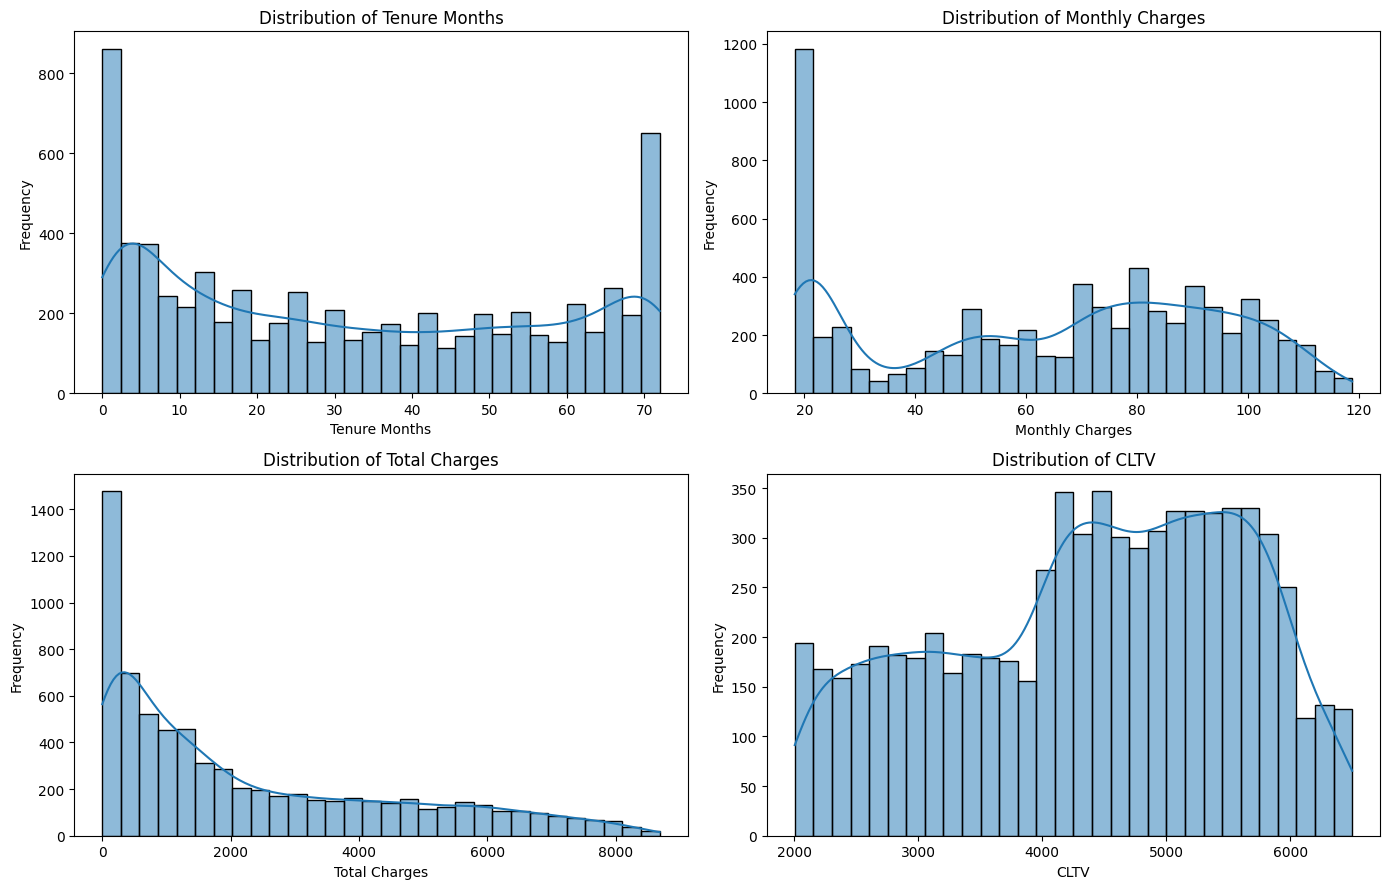

In [26]:
# Plot histograms for numerical measurement variables

measurement_columns = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "CLTV"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for column, ax in zip(measurement_columns, axes.flatten()):
    sns.histplot(
        data=df_clean,
        x=column,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

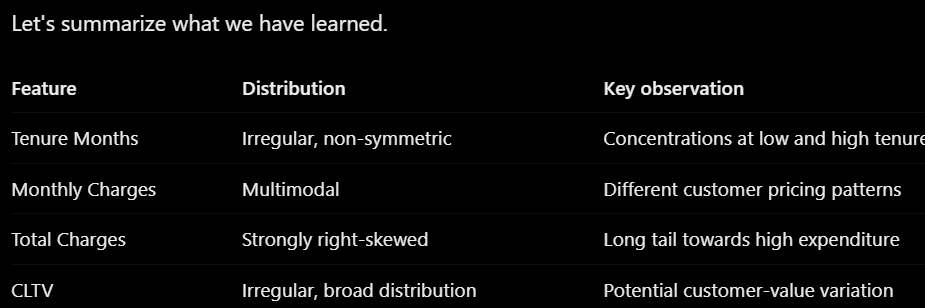

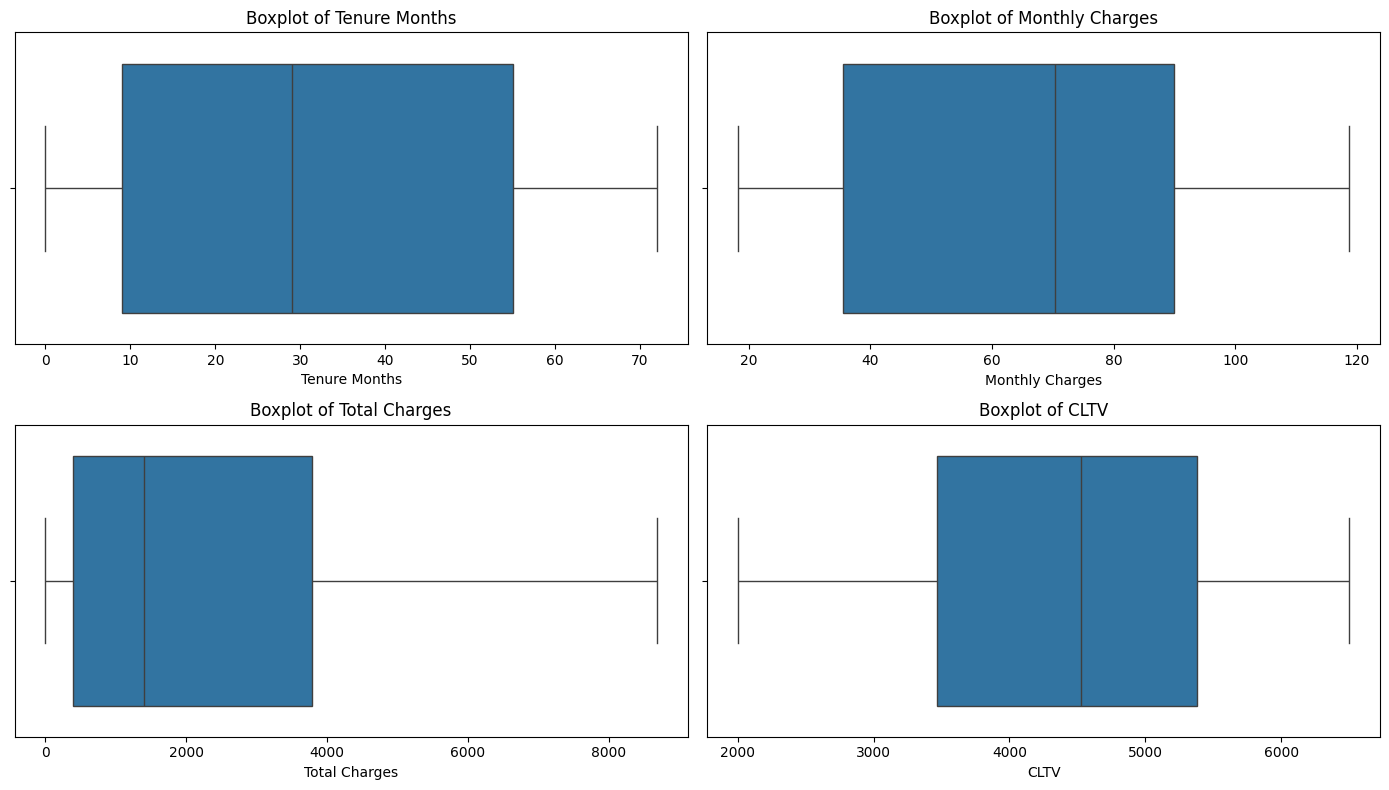

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for column, ax in zip(measurement_columns, axes.flatten()):
    sns.boxplot(
        data=df_clean,
        x=column,
        ax=ax
    )

    ax.set_title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

In [28]:
outlier_summary = []

for column in measurement_columns:

    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": column,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary

,Feature,IQR,Lower Bound,Upper Bound,Outlier Count
0,Tenure Months,46.00,-60.000,124.000,0
1,Monthly Charges,54.35,-46.025,171.375,0
2,Total Charges,3388.05,-4683.525,8868.675,0
3,CLTV,1911.50,601.750,8247.750,0


### Observation: Outlier Analysis

The numerical measurement variables were examined using boxplots and
the Interquartile Range (IQR) method.

The outlier boundaries were calculated using:

Lower Bound = Q1 - 1.5 × IQR
Upper Bound = Q3 + 1.5 × IQR

The analysis identified zero potential outliers in:

- Tenure Months
- Monthly Charges
- Total Charges
- CLTV

All observed values lie within their respective IQR boundaries.

No outlier removal or capping is required based on this analysis.
However, the absence of IQR-defined outliers does not establish that
all observations are error-free.

### Understand the target distribution

In [29]:
# Count customers in each churn category
churn_counts = df_clean["Churn Label"].value_counts()

# Calculate class percentages
churn_percentages = df_clean["Churn Label"].value_counts(normalize=True) * 100

# Combine both into a summary
churn_summary = pd.DataFrame({
    "Customer Count": churn_counts,
    "Percentage": churn_percentages
})

churn_summary

,Customer Count,Percentage
Churn Label,,
No,5174,73.463013
Yes,1869,26.536987


### Visualize the target distribution

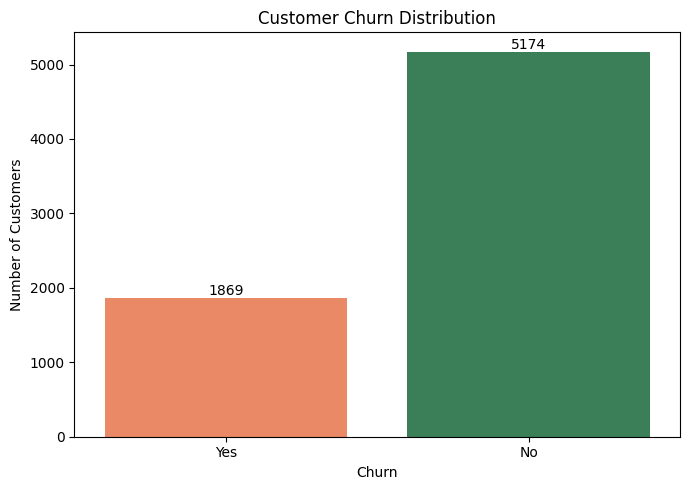

In [30]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df_clean,
    x="Churn Label",
    hue="Churn Label",
    palette={"No": "seagreen", "Yes": "coral"},
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

### Observation: Target Variable Distribution

The target variable `Churn Label` contains two classes:

- No: 5,174 customers (73.46%)
- Yes: 1,869 customers (26.54%)

The dataset exhibits class imbalance, with non-churned customers
representing the majority class.

A model predicting only the majority class would achieve an accuracy
of approximately 73.46%, despite failing to identify any churned
customers.

Therefore, accuracy alone will not be an adequate evaluation metric.
Recall, precision, F1-score, ROC-AUC and PR-AUC will also be considered.

### Compare tenure across churn classes

In [31]:
df_clean.groupby("Churn Label")["Tenure Months"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
Churn Label,,,,,,
No,5174,37.569965,38.0,24.113777,0,72
Yes,1869,17.979133,10.0,19.531123,1,72


Our preliminary observation is:

Customers with shorter tenure appear more likely to churn than customers with longer tenure.

This is an association, not proof that shorter tenure causes churn.

### Visualize tenure against churn

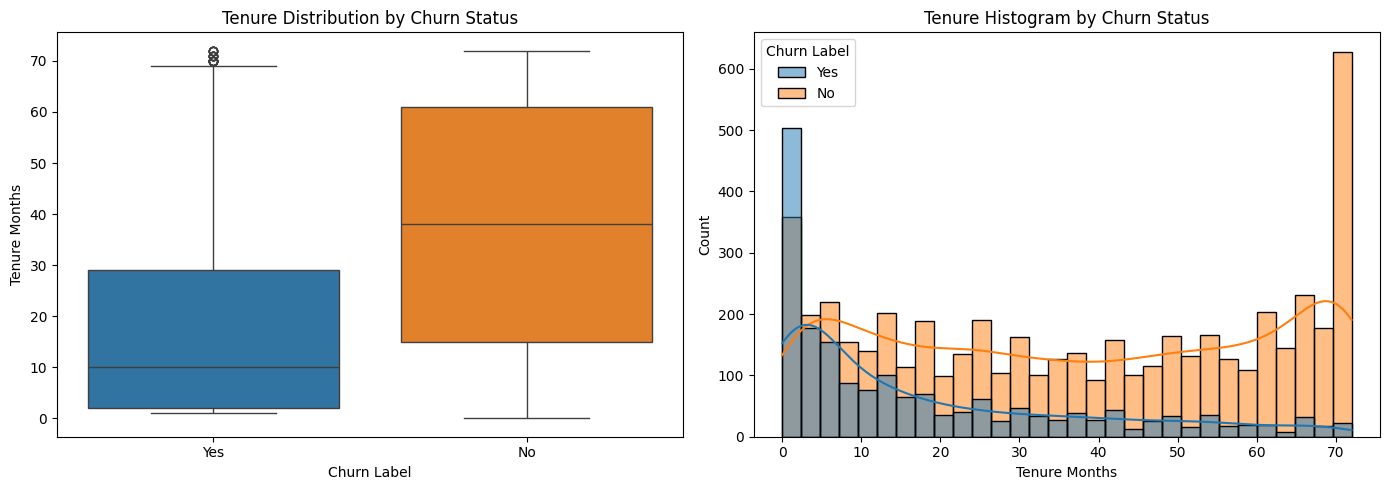

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot
sns.boxplot(
    data=df_clean,
    x="Churn Label",
    y="Tenure Months",
    hue="Churn Label",
    ax=axes[0],
    legend=False
)

axes[0].set_title("Tenure Distribution by Churn Status")

# Histogram
sns.histplot(
    data=df_clean,
    x="Tenure Months",
    hue="Churn Label",
    bins=30,
    kde=True,
    common_norm=False,
    ax=axes[1]
)

axes[1].set_title("Tenure Histogram by Churn Status")

plt.tight_layout()
plt.show()

### Interpret tenure versus churn  
1. BOXPLOT

Look at the median values:
* Churn = Yes: median tenure is 10 months.
* Churn = No: median tenure is 38 months.

The difference is substantial.

Other observations:
- The middle 50% of churned customers are concentrated at relatively low tenure values.
- Non-churned customers have a much higher tenure distribution.
- A few high-tenure churned customers appear as potential outliers under the boxplot's 1.5 × IQR rule.
Notice something interesting: earlier, our overall tenure analysis identified zero outliers. Now, the churned subgroup has some high-tenure outliers.

This is perfectly possible because the IQR boundaries change when we divide the dataset into groups.

2. Histogram

The histogram reinforces the boxplot observations.

Churn = Yes:
- A very large concentration occurs at low tenure.
- The frequency of churned customers generally decreases as tenure increases.
- Relatively few churned customers have very high tenure.
Churn = No:
- Customers are distributed across a much wider tenure range.
- There is a substantial concentration near 70–72 months.
- Long-tenure customers are more prominent in this group.
However, remember that this histogram displays customer counts, not churn probabilities.

### An important distinction: Counts versus churn rates

Suppose we observe 500 churned customers with tenure below 10 months.

That number alone doesn't tell us the probability of churn.

We also need to know how many total customers have tenure below 10 months.

### Calculate churn rates across tenure groups

In [33]:
# Define tenure groups
tenure_bins = [0, 12, 24, 36, 48, 60, 72]

# Create tenure categories
df_clean["Tenure Group"] = pd.cut(
    df_clean["Tenure Months"],
    bins=tenure_bins,
    include_lowest=True
)

# Calculate churn statistics
tenure_churn = df_clean.groupby(
    "Tenure Group",
    observed=False).agg(
        Total_Customers=("Churn Label", "count"),
        Churned_Customers=("Churn Value", "sum")
    )

# Calculate churn percentage
tenure_churn["Churn Rate (%)"] = (
    tenure_churn["Churned_Customers"]
    / tenure_churn["Total_Customers"]
    * 100
)

tenure_churn

,Total_Customers,Churned_Customers,Churn Rate (%)
Tenure Group,,,
"(-0.001, 12.0]",2186,1037,47.438243
"(12.0, 24.0]",1024,294,28.710938
"(24.0, 36.0]",832,180,21.634615
"(36.0, 48.0]",762,145,19.028871
"(48.0, 60.0]",832,120,14.423077
"(60.0, 72.0]",1407,93,6.609808


### Interpret churn rate across tenure groups

### Document the findings

#### Observation: Customer Tenure vs Churn

Customer churn rates were calculated across six tenure intervals.

The following trend was observed:

- 0–12 months: 47.44%
- 12–24 months: 28.71%
- 24–36 months: 21.63%
- 36–48 months: 19.03%
- 48–60 months: 14.42%
- 60–72 months: 6.61%

The churn rate decreases consistently with increasing customer tenure.

Customers in their first 12 months exhibit the highest churn rate,
while customers with 60–72 months of tenure exhibit the lowest.

This indicates a strong association between customer tenure and
churn behaviour.

From a business perspective, early customer retention may be an
important area for intervention.

These findings represent associations and do not establish causation.

### Visualize the churn-rate trend

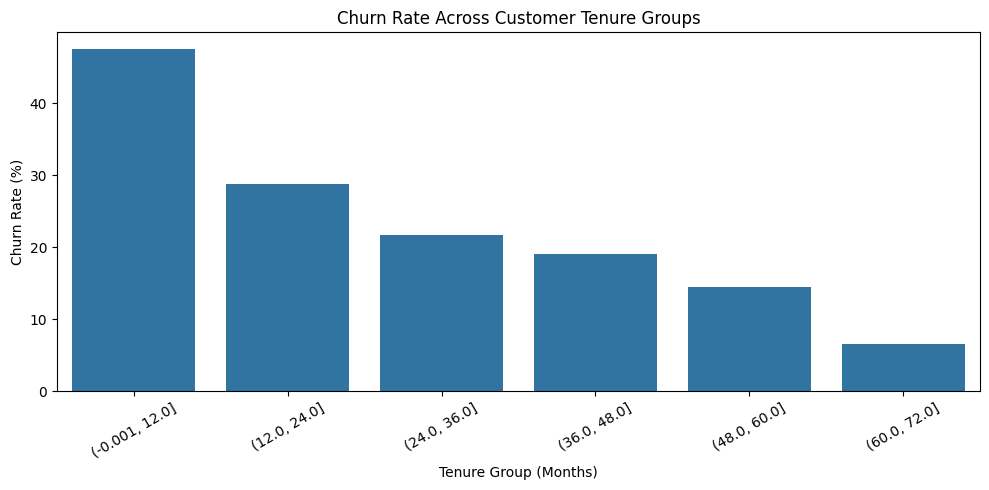

In [34]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tenure_churn.reset_index(),
    x="Tenure Group",
    y="Churn Rate (%)"
)

plt.title("Churn Rate Across Customer Tenure Groups")
plt.xlabel("Tenure Group (Months)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

The key business insight: The first 12 months represent a particularly vulnerable period in the customer lifecycle. Retention efforts during this period may deserve greater attention.

### Monthly Charges vs Churn

### Compare descriptive statistics

In [35]:
df_clean.groupby("Churn Label")["Monthly Charges"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
Churn Label,,,,,,
No,5174,61.265124,64.425,31.092648,18.25,118.75
Yes,1869,74.441332,79.650,24.666053,18.85,118.35


### Interpret Monthly Charges vs Churn

1. Mean monthly charges
- Non-churned customers: $61.27
- Churned customers: $74.44
The average monthly charge of churned customers is approximately $13.18 higher.
2. Median monthly charges
- Non-churned customers: $64.43
- Churned customers: $79.65
The median difference is approximately $15.23.

This reinforces the observation that churned customers tend to have higher monthly charges.
3. Standard deviation
- Non-churned: $31.09
- Churned: $24.67

Monthly charges among non-churned customers show greater absolute variation.
4. Preliminary business interpretation
Higher monthly charges may be associated with increased churn.

Possible explanations worth investigating include:
- Higher subscription costs.
- Differences in subscribed services.
- Differences in contract types.
- Customer sensitivity to pricing.
However, we cannot conclude that higher charges cause churn. We need to investigate the relationships with other variables.

### Visualize Monthly Charges by churn status

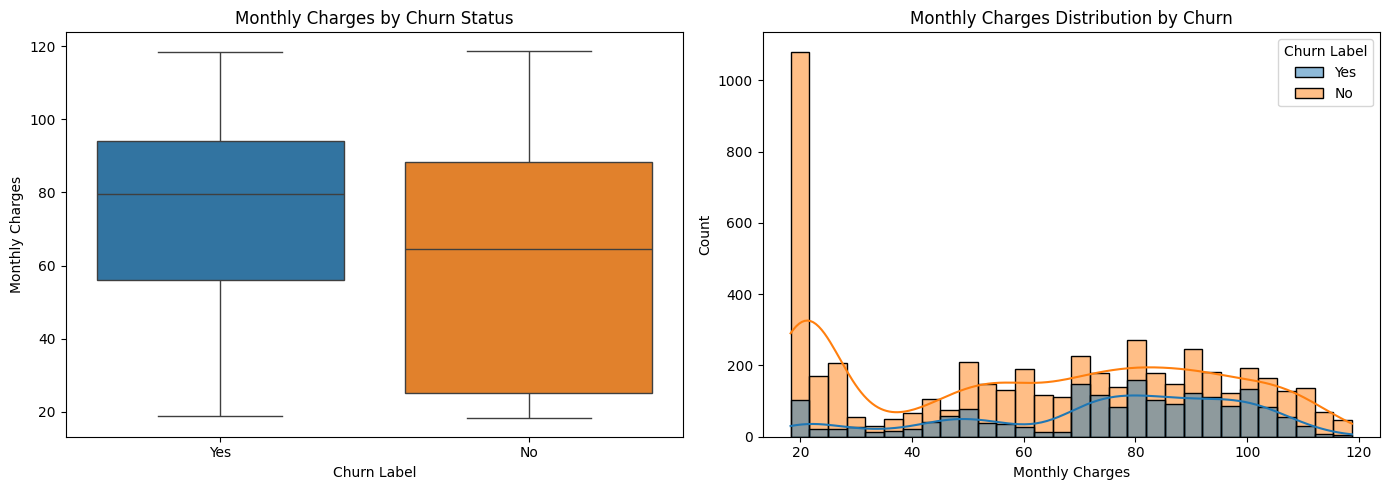

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot
sns.boxplot(
    data=df_clean,
    x="Churn Label",
    y="Monthly Charges",
    hue="Churn Label",
    ax=axes[0],
    legend=False
)

axes[0].set_title("Monthly Charges by Churn Status")

# Histogram
sns.histplot(
    data=df_clean,
    x="Monthly Charges",
    hue="Churn Label",
    bins=30,
    kde=True,
    common_norm=False,
    ax=axes[1]
)

axes[1].set_title("Monthly Charges Distribution by Churn")

plt.tight_layout()
plt.show()

### Interpret Monthly Charges vs Churn

1. Boxplot
The median monthly charges are:
- Churn = Yes: $79.65
- Churn = No: $64.43
The difference is approximately $15.23.

Other observations:
- The first quartile of churned customers is higher than that of non-churned customers.
- The median of churned customers is also higher.
- There is substantial overlap between the distributions.
- Both groups have similar minimum and maximum values.
This suggests that monthly charges are associated with churn, but they cannot independently distinguish every churned customer from every non-churned customer.

2. Histogram
We can observe:
- A large concentration of non-churned customers around $20.
- Churned customers are more concentrated in the higher monthly-charge ranges.
- Both groups have substantial representation between approximately $70 and $105.
- The distributions overlap considerably.
The histogram supports our earlier observation, although it displays counts rather than churn probabilities.
3. Business interpretation
Higher monthly charges may be associated with increased churn risk.

One possible explanation is that customers paying more may be more sensitive to pricing or may have different service combinations.

However, we need to investigate contract type and subscribed services before making stronger interpretations.

### Calculate churn rates across monthly-charge groups

In [37]:
# Define monthly charge intervals
charge_bins = [0, 30, 50, 70, 90, 120]

# Create monthly charge groups
df_clean["Monthly Charge Group"] = pd.cut(
    df_clean["Monthly Charges"],
    bins=charge_bins,
    include_lowest=True
)

# Calculate churn statistics
charge_churn = df_clean.groupby(
    "Monthly Charge Group",
    observed=False
).agg(
    Total_Customers=("Churn Label", "count"),
    Churned_Customers=("Churn Value", "sum")
)

# Calculate churn rate
charge_churn["Churn Rate (%)"] = (
    charge_churn["Churned_Customers"]
    / charge_churn["Total_Customers"]
    * 100
)

charge_churn

,Total_Customers,Churned_Customers,Churn Rate (%)
Monthly Charge Group,,,
"(-0.001, 30.0]",1653,162,9.800363
"(30.0, 50.0]",646,199,30.804954
"(50.0, 70.0]",1161,241,20.757967
"(70.0, 90.0]",1844,697,37.798265
"(90.0, 120.0]",1739,570,32.777458


### Interpret churn rate across monthly-charge groups

1. Lowest monthly charges: 9.80% churn  
Customers paying up to $30 have the lowest churn rate. This is consistent with the large concentration of non-churned customers around $20 in our histogram.  
2. $30–$50: churn increases to 30.80%  
There is a substantial increase compared with the lowest charge group.  
3. $50–$70: churn decreases to 20.76%  
This is an important observation. Although monthly charges have increased, churn rate has decreased.  
4. $70–$90: highest churn rate  
This group has a churn rate of 37.80%, the highest among the five intervals.  
5. $90–$120: churn decreases to 32.78%  
Despite having the highest monthly charges, this group does not have the highest churn rate.

### Observation: Monthly Charges vs Churn

Churn rates were calculated across five monthly-charge intervals.

- $0–$30: 9.80%
- $30–$50: 30.80%
- $50–$70: 20.76%
- $70–$90: 37.80%
- $90–$120: 32.78%

The $70–$90 interval exhibits the highest churn rate, while the
lowest monthly-charge interval exhibits the lowest churn rate.

The relationship between monthly charges and churn is non-monotonic.
Churn rates do not increase consistently with increasing monthly charges.

This suggests that monthly charges alone may not adequately explain
customer churn. Other variables, including contract type and subscribed
services, should be investigated.

These findings represent associations and do not establish causation.

### Contract type versus churn

In [38]:
contract_churn = df_clean.groupby("Contract").agg(
    Total_Customers=("Churn Label", "count"),
    Churned_Customers=("Churn Value", "sum")
)

contract_churn["Churn Rate (%)"] = (
    contract_churn["Churned_Customers"]
    / contract_churn["Total_Customers"]
    * 100
)

contract_churn

,Total_Customers,Churned_Customers,Churn Rate (%)
Contract,,,
Month-to-month,3875,1655,42.709677
One year,1473,166,11.269518
Two year,1695,48,2.831858


Customers on month-to-month contracts may have greater flexibility to discontinue their subscriptions.

Customers on longer contracts have a longer-term commitment, which may be associated with lower observed churn.

However, we must be careful about causation. Customers who are already more loyal or satisfied may also be more likely to choose longer contracts.

We cannot conclude from this analysis alone that moving customers to longer contracts will necessarily prevent churn.

### Visualize the results

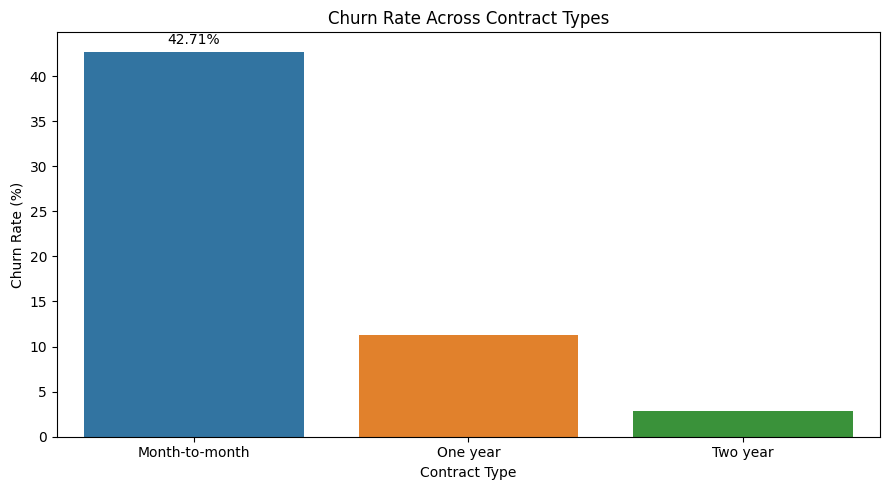

In [39]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=contract_churn.reset_index(),
    x="Contract",
    y="Churn Rate (%)",
    hue="Contract",
    legend=False
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f%%",
    padding=3
)

plt.title("Churn Rate Across Contract Types")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

### Observation: Contract Type vs Churn

Churn rates were calculated across three contract categories:

- Month-to-month: 42.71%
- One year: 11.27%
- Two year: 2.83%

A substantial decline in churn rate is observed with increasing
contract duration.

Month-to-month customers exhibit the highest churn rate, whereas
two-year contract customers exhibit the lowest.

Contract type appears to be an important feature associated with
customer churn.

This relationship may reflect differences in customer commitment,
flexibility, satisfaction, or other underlying characteristics.
The analysis establishes association, not causation.

### Payment Method versus Churn

In [40]:
payment_churn = df_clean.groupby("Payment Method").agg(
    Total_Customers=("Churn Label", "count"),
    Churned_Customers=("Churn Value", "sum")
)

payment_churn["Churn Rate (%)"] = (
    payment_churn["Churned_Customers"]
    / payment_churn["Total_Customers"]
    * 100
)

payment_churn

,Total_Customers,Churned_Customers,Churn Rate (%)
Payment Method,,,
Bank transfer (automatic),1544,258,16.709845
Credit card (automatic),1522,232,15.243101
Electronic check,2365,1071,45.285412
Mailed check,1612,308,19.106700


### Interpret payment method versus churn

1. Electronic check
- Total customers: 2,365
- Churned customers: 1,071
- Churn rate: 45.29%
This is considerably higher than the other payment methods.
2. Mailed check
- Total customers: 1,612
- Churned customers: 308
- Churn rate: 19.11%
3. Automatic bank transfer
- Total customers: 1,544
- Churned customers: 258
- Churn rate: 16.71%
4. Automatic credit card
- Total customers: 1,522
- Churned customers: 232
- Churn rate: 15.24%

### Business interpretation
This is a potentially valuable finding.

Customers using automatic payment methods exhibit substantially lower observed churn than customers using electronic checks.

Possible explanations worth investigating:
- Automatic payments may reduce payment friction.
- Customers using automatic payments may have different levels of engagement.
- Payment method may be associated with contract type or customer tenure.
- Customers choosing electronic checks may have different customer characteristics.
We should not conclude that switching customers to automatic payments will necessarily reduce churn. Other variables may explain some or all of this association.

### Observation: Payment Method vs Churn

Churn rates were calculated across four payment methods:

- Electronic check: 45.29%
- Mailed check: 19.11%
- Bank transfer (automatic): 16.71%
- Credit card (automatic): 15.24%

Customers using electronic checks exhibit a substantially higher
churn rate than customers using other payment methods.

Automatic payment methods exhibit comparatively lower churn rates.

Payment method appears to be an informative feature associated
with customer churn.

Further investigation is required to understand its relationship
with contract type, tenure, and other customer characteristics.
These findings establish association, not causation.

### Internet Service versus Churn

In [41]:
internet_churn = df_clean.groupby("Internet Service").agg(
    Total_Customers=("Churn Label", "count"),
    Churned_Customers=("Churn Value", "sum")
)

internet_churn["Churn Rate (%)"] = (
    internet_churn["Churned_Customers"]
    / internet_churn["Total_Customers"]
    * 100
)

internet_churn

,Total_Customers,Churned_Customers,Churn Rate (%)
Internet Service,,,
DSL,2421,459,18.959108
Fiber optic,3096,1297,41.892765
No,1526,113,7.404980


### Interpret Internet Service versus Churn

1. DSL
- Total customers: 2,421
- Churned customers: 459
- Churn rate: 18.96%
2. Fiber optic
- Total customers: 3,096
- Churned customers: 1,297
- Churn rate: 41.89%
This is the highest churn rate among the three categories.
3. No internet service
- Total customers: 1,526
- Churned customers: 113
- Churn rate: 7.40%
This group has the lowest churn rate.

### What can we infer?

Some interesting observations:
1. Fiber optic customers have approximately 2.2 times the churn rate of DSL customers.
2. Customers without internet service have the lowest observed churn rate.
3. Internet service type appears to be an informative feature for predicting churn.
However, we should not conclude that fiber optic service itself causes churn.

For example, fiber optic customers may have higher monthly charges, different service combinations, or different contract preferences.

We should investigate these relationships before drawing business conclusions.

### Observation: Internet Service vs Churn

Churn rates were calculated across three internet service categories:

- DSL: 18.96%
- Fiber optic: 41.89%
- No internet service: 7.40%

Customers using fiber optic internet exhibit the highest churn rate,
while customers without internet service exhibit the lowest.

Fiber optic customers have approximately 2.2 times the churn rate
of DSL customers.

Internet service type appears to be an informative feature associated
with customer churn.

Further investigation is required to understand its relationship with
monthly charges, contract type, and other customer characteristics.

These findings represent associations and do not establish causation.

### Internet-related services vs Churn

In [42]:
# Create a reusable churn-analysis function

def calculate_churn_rate(data, feature):

    summary = data.groupby(feature).agg(
        Total_Customers=("Churn Label", "count"),
        Churned_Customers=("Churn Value", "sum")
    )

    summary["Churn Rate (%)"] = (
        summary["Churned_Customers"]
        / summary["Total_Customers"]
        * 100
    )

    return summary

In [43]:
calculate_churn_rate(df_clean, "Online Security")

,Total_Customers,Churned_Customers,Churn Rate (%)
Online Security,,,
No,3498,1461,41.766724
No internet service,1526,113,7.404980
Yes,2019,295,14.611194


### Interpret Online Security versus Churn

1. Customers without Online Security
- Total customers: 3,498
- Churned customers: 1,461
- Churn rate: 41.77%
This is the highest churn rate.
2. Customers with Online Security
- Total customers: 2,019
- Churned customers: 295
- Churn rate: 14.61%
The churn rate is substantially lower.
3. Customers without internet service
- Total customers: 1,526
- Churned customers: 113
- Churn rate: 7.40%
This is the lowest rate.

### Business interpretation

Customers without Online Security have approximately 2.86 times the churn rate of customers with Online Security.

This is a strong association, but we shouldn't conclude that subscribing to Online Security prevents churn.

For example, customers subscribing to additional services may also have longer contracts or different customer characteristics.

### Observation: Online Security vs Churn

Churn rates were calculated across three categories:

- No: 41.77%
- Yes: 14.61%
- No internet service: 7.40%

Customers without Online Security exhibit substantially higher
churn rates than customers subscribed to the service.

Customers without internet service exhibit the lowest churn rate.

The results suggest that Online Security subscription status is
strongly associated with customer churn.

Further investigation is required to understand its relationship
with contract type, tenure, and other subscribed services.

These findings establish association, not causation.

### Online Backup vs Churn

In [44]:
calculate_churn_rate(df_clean, "Online Backup")

,Total_Customers,Churned_Customers,Churn Rate (%)
Online Backup,,,
No,3088,1233,39.928756
No internet service,1526,113,7.404980
Yes,2429,523,21.531494


Customers without Online Backup exhibit a higher churn rate (39.93%) compared to customers with Online Backup (21.53%). Customers without internet service have a substantially lower churn rate (7.40%). This suggests an association between Online Backup subscription and customer retention. However, the relationship may be influenced by other factors, such as contract type, tenure, and service combinations, and should not be interpreted as causal.

### Device Protection vs Churn

In [45]:
calculate_churn_rate(df_clean, "Device Protection")

,Total_Customers,Churned_Customers,Churn Rate (%)
Device Protection,,,
No,3095,1211,39.127625
No internet service,1526,113,7.404980
Yes,2422,545,22.502064


Customers without Device Protection exhibit a higher churn rate (39.13%) than customers subscribed to the service (22.50%). Customers without internet service have a substantially lower churn rate (7.40%). This indicates an association between Device Protection subscription and customer retention. However, the relationship may be influenced by other factors, including contract type, tenure, and the combination of services subscribed to by customers.

### Tech Support vs Churn

In [46]:
calculate_churn_rate(df_clean, "Tech Support")

,Total_Customers,Churned_Customers,Churn Rate (%)
Tech Support,,,
No,3473,1446,41.635474
No internet service,1526,113,7.404980
Yes,2044,310,15.166341


Customers without Tech Support exhibit a substantially higher churn rate (41.64%) compared to customers subscribed to the service (15.17%). The difference of approximately 26.47 percentage points represents a strong association between Tech Support subscription and customer retention. This may indicate the importance of technical assistance in customer satisfaction. However, the relationship could also be influenced by other factors, such as contract type, tenure, and internet service type.

### Streaming TV vs Churn

In [47]:
calculate_churn_rate(df_clean, "Streaming TV")

,Total_Customers,Churned_Customers,Churn Rate (%)
Streaming TV,,,
No,2810,942,33.523132
No internet service,1526,113,7.404980
Yes,2707,814,30.070188


Customers without Streaming TV exhibit a churn rate of 33.52%, compared to 30.07% among customers subscribed to the service. The relatively small difference of approximately 3.45 percentage points suggests a weaker association with churn compared to features such as Tech Support and Online Security. Therefore, Streaming TV subscription alone may have limited discriminatory value for identifying churn patterns. Further analysis involving other customer and account characteristics is required.

### Streaming Movies vs Churn

In [48]:
calculate_churn_rate(df_clean, "Streaming Movies")

,Total_Customers,Churned_Customers,Churn Rate (%)
Streaming Movies,,,
No,2785,938,33.680431
No internet service,1526,113,7.404980
Yes,2732,818,29.941435


Customers without Streaming Movies exhibit a churn rate of 33.68%, compared to 29.94% among customers subscribed to the service. The relatively small difference of approximately 3.74 percentage points suggests a weak individual association between Streaming Movies subscription and churn. This is consistent with the pattern observed for Streaming TV. Therefore, these features may have limited individual discriminatory value, although their combined contribution or interactions with other features may still be useful for prediction.

### Phone Service vs Churn

In [49]:
calculate_churn_rate(df_clean, "Phone Service")

,Total_Customers,Churned_Customers,Churn Rate (%)
Phone Service,,,
No,682,170,24.926686
Yes,6361,1699,26.709637


Customers with Phone Service exhibit a churn rate of 26.71%, compared to 24.93% among customers without the service. The relatively small difference of approximately 1.78 percentage points suggests a weak individual association between Phone Service subscription and churn. However, the relationship may differ depending on whether customers subscribe to Multiple Lines, which warrants further investigation.

### Multiple Lines vs Churn

In [50]:
calculate_churn_rate(df_clean, "Multiple Lines")

,Total_Customers,Churned_Customers,Churn Rate (%)
Multiple Lines,,,
No,3390,849,25.044248
No phone service,682,170,24.926686
Yes,2971,850,28.609896


Customers with Multiple Lines exhibit a churn rate of 28.61%, compared to 25.04% among customers without Multiple Lines. The difference of approximately 3.57 percentage points indicates a relatively weak individual association with churn. Customers without Phone Service have a churn rate of 24.93%, which is nearly identical to the No category. Overall, Multiple Lines alone does not appear to be a particularly strong indicator of churn.

### Demographic features vs Churn

In [51]:
calculate_churn_rate(df_clean, "Senior Citizen")

,Total_Customers,Churned_Customers,Churn Rate (%)
Senior Citizen,,,
No,5901,1393,23.606168
Yes,1142,476,41.681261


Senior citizens exhibit a substantially higher churn rate (41.68%) compared to non-senior customers (23.61%). The difference of approximately 18.08 percentage points indicates a relatively strong association between senior-citizen status and customer churn. Although senior citizens constitute only around 16.2% of the customer base, they account for approximately 25.5% of churned customers. Further investigation is required to understand the influence of other customer and account characteristics on this relationship.

### Partner vs Churn

In [52]:
calculate_churn_rate(df_clean, "Partner")

,Total_Customers,Churned_Customers,Churn Rate (%)
Partner,,,
No,3641,1200,32.957979
Yes,3402,669,19.664903


Customers without a partner exhibit a higher churn rate (32.96%) compared to customers with a partner (19.66%). The difference of approximately 13.29 percentage points indicates a meaningful association between partner status and customer churn. This relationship may reflect differences in household characteristics, tenure, or subscription preferences. Further analysis involving other demographic and account-related features is required before drawing conclusions about its independent predictive contribution.

### Dependants vs Churn

In [53]:
calculate_churn_rate(df_clean, "Dependents")

,Total_Customers,Churned_Customers,Churn Rate (%)
Dependents,,,
No,5416,1763,32.551699
Yes,1627,106,6.515058


Customers without dependents exhibit a substantially higher churn rate (32.55%) compared to customers with dependents (6.52%). The difference of approximately 26.04 percentage points indicates a strong association between dependent status and customer churn. Customers with dependents constitute approximately 23.1% of the customer base but account for only 5.7% of churned customers. This relationship may be influenced by other demographic and account characteristics, particularly partner status, contract type, and tenure.

### Gender vs Churn

In [54]:
calculate_churn_rate(df_clean, "Gender")

,Total_Customers,Churned_Customers,Churn Rate (%)
Gender,,,
Female,3488,939,26.920872
Male,3555,930,26.160338


Female customers exhibit a churn rate of 26.92%, compared to 26.16% among male customers. The difference of approximately 0.76 percentage points indicates a negligible association between gender and customer churn in this dataset. Therefore, Gender appears to have limited individual discriminatory value for churn analysis, although its contribution should ultimately be evaluated within a multivariate predictive model.

### Paperless Billing vs Churn

In [55]:
calculate_churn_rate(df_clean, "Paperless Billing")

,Total_Customers,Churned_Customers,Churn Rate (%)
Paperless Billing,,,
No,2872,469,16.330084
Yes,4171,1400,33.565092


Customers subscribed to Paperless Billing exhibit a higher churn rate (33.57%) compared to customers who do not use the service (16.33%). The difference of approximately 17.24 percentage points indicates a meaningful association between Paperless Billing and customer churn. However, this relationship may be influenced by other account characteristics, particularly contract type, payment method, and tenure. Therefore, the observed association should not be interpreted as a causal relationship.

### Let's investigate whether Paperless Billing and Contract are related

In [56]:
pd.crosstab(
    df_clean["Paperless Billing"],
    df_clean["Contract"],
    normalize="index"
) * 100

Contract,Month-to-month,One year,Two year
Paperless Billing,,,
No,44.881616,23.433148,31.685237
Yes,61.999520,19.180053,18.820427


Key observations:
1. Among customers using Paperless Billing, 62% have month-to-month contracts.
2. Among customers not using Paperless Billing, only 44.88% have month-to-month contracts.
3. The proportion of two-year contract customers is considerably lower among paperless-billing customers (18.82%) than among non-paperless customers (31.69%).
4. Thus, paperless-billing customers are more concentrated in month-to-month contracts.

Why is this important?
Recall our earlier findings:
- Month-to-month contract churn rate: 42.71%
- One-year contract churn rate: 11.27%
- Two-year contract churn rate: 2.83%

We now have two observations:
- Paperless Billing customers have a higher overall churn rate.
- Paperless Billing customers are more likely to have month-to-month contracts.
This suggests that Contract Type could partly explain the higher churn rate observed among Paperless Billing customers.

However, we have not yet established how much of the difference is explained by contract type. We need to compare churn rates within each contract category.

### Let's verify this with a cross-analysis

In [57]:
pd.crosstab(
    [df_clean["Paperless Billing"], df_clean["Contract"]],
    df_clean["Churn Label"],
    normalize="index"
) * 100

Churn Label                              No        Yes
Paperless Billing Contract                            
No                Month-to-month  68.502715  31.497285
                  One year        92.867756   7.132244
                  Two year        98.351648   1.648352
Yes               Month-to-month  51.701469  48.298531
                  One year        85.250000  14.750000
                  Two year        95.796178   4.203822

A cross-analysis of Paperless Billing and Contract Type reveals that paperless-billing customers exhibit higher churn rates across all three contract categories. For month-to-month, one-year, and two-year contracts, the respective churn rates are 48.30%, 14.75%, and 4.20% among paperless-billing customers, compared to 31.50%, 7.13%, and 1.65% among non-paperless customers. Although paperless-billing customers are more concentrated in month-to-month contracts, contract composition alone does not explain the observed association with churn. Other customer and account characteristics may also contribute to this relationship.

### A useful distinction for the project
What we just performed is called stratified analysis: we divided customers into groups based on Contract Type and compared churn rates within each group.

This is a useful step before modeling because it helps us identify relationships that may be hidden or distorted in an overall comparison.

We will eventually use multivariate analysis and feature importance methods to investigate these relationships further.

### Payment Method and Contract Type

In [58]:
pd.crosstab(
    df_clean["Payment Method"],
    df_clean["Contract"],
    normalize="index"
) * 100

Contract,Month-to-month,One year,Two year
Payment Method,,,
Bank transfer (automatic),38.147668,25.323834,36.528497
Credit card (automatic),35.676741,26.149803,38.173456
Electronic check,78.224101,14.672304,7.103594
Mailed check,55.397022,20.905707,23.697270


Key observations:
1. Electronic Check: Approximately 78.22% of customers using this payment method have month-to-month contracts. Only 7.10% have two-year contracts.
2. Automatic payments: Customers using automatic bank transfers and credit cards have relatively similar contract distributions. Around 36–38% have month-to-month contracts, while approximately 36–38% have two-year contracts.
3. Mailed Check: 55.40% of these customers have month-to-month contracts, which is higher than both automatic-payment groups.
4. Electronic-check customers are particularly concentrated in month-to-month contracts.

In [59]:
pd.crosstab(
    [df_clean["Payment Method"], df_clean["Contract"]],
    df_clean["Churn Label"],
    normalize="index"
) * 100

Churn Label                                      No        Yes
Payment Method            Contract                            
Bank transfer (automatic) Month-to-month  65.874363  34.125637
                          One year        90.281330   9.718670
                          Two year        96.631206   3.368794
Credit card (automatic)   Month-to-month  67.219153  32.780847
                          One year        89.698492  10.301508
                          Two year        97.762478   2.237522
Electronic check          Month-to-month  46.270270  53.729730
                          One year        81.556196  18.443804
                          Two year        92.261905   7.738095
Mailed check              Month-to-month  68.421053  31.578947
                          One year        93.175074   6.824926
                          Two year        99.214660   0.785340

Stratified analysis of Payment Method and Contract Type reveals that customers using Electronic Check exhibit consistently higher churn rates across all three contract categories. For month-to-month, one-year, and two-year contracts, the churn rates among electronic-check customers are 53.73%, 18.44%, and 7.74%, respectively. These rates are considerably higher than those observed for other payment methods within the same contract categories. Although electronic-check customers are disproportionately concentrated in month-to-month contracts, contract composition alone does not explain their higher churn rates. This suggests that Payment Method contains additional information associated with churn, although further multivariate analysis is required to investigate its independent contribution.

### Partner and Dependents

In [60]:
pd.crosstab(
    df_clean["Partner"],
    df_clean["Dependents"],
    normalize="index"
) * 100

Dependents,No,Yes
Partner,,
No,91.705575,8.294425
Yes,61.052322,38.947678


Key observations:
1. Among customers without a partner, only 8.29% have dependents.
2. Among customers with a partner, 38.95% have dependents.
3. Customers with a partner are substantially more likely to have dependents.
4. Therefore, Partner and Dependents are not independent demographic features; they have a noticeable relationship.

Why does this matter for churn analysis?
Recall the churn rates we calculated:
- Customers without a partner: 32.96%
- Customers with a partner: 19.66%
- Customers without dependents: 32.55%
- Customers with dependents: 6.52%

We now know that customers with partners are much more likely to have dependents.

Since customers with dependents have a particularly low churn rate, this demographic relationship could partly explain the lower overall churn rate among customers with partners.

In other words, the observed Partner–Churn relationship may partly reflect the influence of Dependents.

We should verify this rather than assume it.

In [61]:
pd.crosstab(
    [df_clean["Partner"], df_clean["Dependents"]],
    df_clean["Churn Label"],
    normalize="index"
) * 100

Churn Label                No        Yes
Partner Dependents                      
No      No          65.558550  34.441450
        Yes         83.443709  16.556291
Yes     No          70.486278  29.513722
        Yes         95.773585   4.226415

Stratified analysis of Partner and Dependents reveals that customers with a partner exhibit lower churn rates within both dependent-status categories. Among customers without dependents, the churn rate is 29.51% for those with a partner, compared to 34.44% for those without a partner. Among customers with dependents, the corresponding churn rates are 4.23% and 16.56%, respectively. Therefore, the association between Partner and Churn persists even after accounting for dependent status at the descriptive level. The difference in the magnitude of this association across the two groups also suggests a possible interaction between these demographic features.

### Correlation Matrix

In [62]:
correlation_columns = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "CLTV"
]

correlation_matrix = df_clean[correlation_columns].corr()

correlation_matrix

,Tenure Months,Monthly Charges,Total Charges,CLTV
Tenure Months,1.000000,0.247900,0.826178,0.396406
Monthly Charges,0.247900,1.000000,0.651174,0.098693
Total Charges,0.826178,0.651174,1.000000,0.342091
CLTV,0.396406,0.098693,0.342091,1.000000


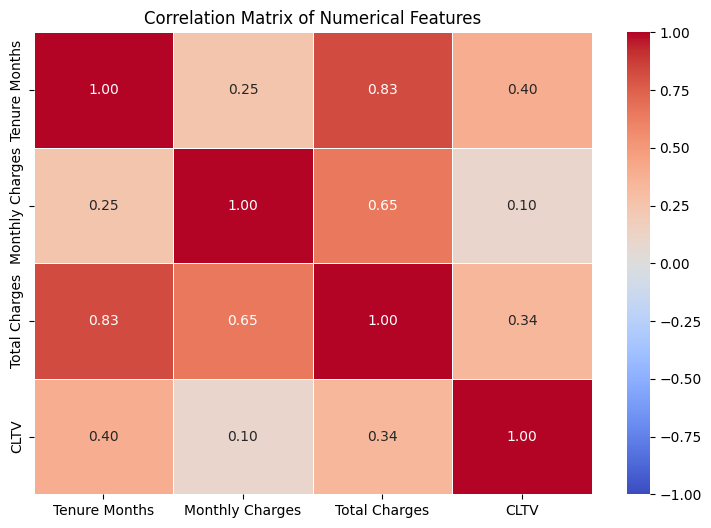

In [63]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Numerical Features")
plt.show()

### Investigate Churn Score

In [64]:
df_clean["Churn Score"].describe()

count    7043.000000
mean       58.699418
std        21.525131
min         5.000000
25%        40.000000
50%        61.000000
75%        75.000000
max       100.000000
Name: Churn Score, dtype: float64

In [65]:
df_clean["Churn Score"].value_counts().sort_index()

Churn Score
5       1
7       2
8       2
9       3
20     83
       ..
96     52
97     64
98     50
99     54
100    50
Name: count, Length: 85, dtype: int64

Observations:
1. The score ranges from 5 to 100.
2. The mean (58.70) and median (61) are relatively close.
3. The standard deviation (21.53) indicates considerable variation between customers.
4. There are 85 distinct score values.
This tells us that Churn Score is not a constant or low-variation feature. However, that alone does not establish its predictive usefulness.

Churn Score is an existing predictive score generated using IBM SPSS Modeler. It ranges from 5 to 100 in this dataset, with higher values indicating a greater likelihood of churn. Since the underlying model, input variables, and prediction-time availability are not sufficiently documented, including this feature could introduce information leakage or dependency on an existing predictive system. Therefore, Churn Score will be excluded from the primary model's feature set.

### Investigate CLTV

In [66]:
df_clean["CLTV"].describe()

count    7043.000000
mean     4400.295755
std      1183.057152
min      2003.000000
25%      3469.000000
50%      4527.000000
75%      5380.500000
max      6500.000000
Name: CLTV, dtype: float64

In [67]:
df_clean["CLTV"].value_counts().sort_index()

CLTV
2003    3
2004    3
2006    1
2007    4
2008    1
       ..
6492    3
6494    2
6495    1
6499    2
6500    1
Name: count, Length: 3438, dtype: int64

#### Let's examine its relationship with churn
Before making a decision, let's see whether CLTV differs substantially between churned and non-churned customers.

In [68]:
df_clean.groupby("Churn Label")["CLTV"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
Churn Label,,,,,,
No,5174,4490.921337,4620.0,1167.703198,2003,6500
Yes,1869,4149.414660,4238.0,1189.370707,2003,6484


Non-churned customers exhibit a higher mean CLTV (4,490.92) compared to churned customers (4,149.41). A similar difference is observed in the median values, with non-churned customers having a median CLTV of 4,620 compared to 4,238 among churned customers. This suggests an association between CLTV and customer churn. However, the distributions overlap substantially, and the provenance and calculation methodology of CLTV must be investigated before considering it as a predictive feature.

`Temporarily exclude`

### Investigate Churn Label and Churn Value

In [69]:
pd.crosstab(
    df_clean["Churn Label"],
    df_clean["Churn Value"]
)

Churn Value,0,1
Churn Label,,
No,5174,0
Yes,0,1869


A cross-tabulation of Churn Label and Churn Value confirms a perfect one-to-one correspondence between the two columns. All 5,174 non-churned customers have a Churn Value of 0, while all 1,869 churned customers have a Churn Value of 1. Therefore, Churn Value will be retained as the binary target variable, and Churn Label will be excluded to avoid redundant target representation.

### Investigate geographic features

We still have:
- City
- Zip Code
- Latitude
- Longitude
- Country
- State
- Lat Long  
  
Country and State are constant throughout the dataset, so they can be excluded.

For the remaining geographic features, let's first understand their cardinality and whether they offer useful information.

In [70]:
df_clean[["City", "Zip Code", "Latitude", "Longitude"]].nunique()

City         1129
Zip Code     1652
Latitude     1652
Longitude    1651
dtype: int64

For the initial model:

Feature	-> Decision -> Reason
Country -> Exclude -> Constant
State -> Exclude -> Constant
Lat Long -> Exclude -> Redundant representation
City -> Exclude initially -> High cardinality
Zip Code -> Exclude initially -> High cardinality
Latitude -> Exclude initially -> Geographic coordinate
Longitude -> Exclude initially -> Geographic coordinate

Why exclude the remaining four initially?
1. One-hot encoding City or Zip Code would create many additional features.
2. Latitude and Longitude may introduce location-specific patterns that are difficult to interpret.
3. We haven't established that geographic location provides meaningful predictive information.
4. We should avoid adding complexity without a clear justification.
This is an initial modeling decision, not proof that geographic information has no predictive value. We can revisit it in a separate experiment.

### Observations

Geographic features were examined for their cardinality and potential redundancy. Country and State contain constant values and therefore provide no discriminatory information. Lat Long is a concatenated representation of Latitude and Longitude and is therefore redundant. City and Zip Code contain 1,129 and 1,652 unique values, respectively, while Latitude and Longitude also exhibit high cardinality. These features will be excluded from the initial model to avoid unnecessary dimensionality and geographic complexity. Their predictive contribution may be investigated separately if required.

In [71]:
df_clean.columns.tolist()

['CustomerID',
 'Count',
 'Country',
 'State',
 'City',
 'Zip Code',
 'Lat Long',
 'Latitude',
 'Longitude',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Tenure Months',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'Churn Label',
 'Churn Value',
 'Churn Score',
 'CLTV',
 'Churn Reason',
 'Tenure Group',
 'Monthly Charge Group']

In [72]:
target_column = "Churn Value"

excluded_columns = [
    "CustomerID",
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude",
    "Churn Label",
    "Churn Score",
    "CLTV",
    "Churn Reason",
    "Tenure Group",
    "Monthly Charge Group"
]

feature_columns = [
    column
    for column in df_clean.columns
    if column not in excluded_columns + [target_column]
]

In [73]:
print("Number of features:", len(feature_columns))

print("\nSelected features:")
for column in feature_columns:
    print(column)

Number of features: 19

Selected features:
Gender
Senior Citizen
Partner
Dependents
Tenure Months
Phone Service
Multiple Lines
Internet Service
Online Security
Online Backup
Device Protection
Tech Support
Streaming TV
Streaming Movies
Contract
Paperless Billing
Payment Method
Monthly Charges
Total Charges


In [74]:
X = df_clean[feature_columns].copy()
y = df_clean[target_column].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (7043, 19)
y shape: (7043,)

Target distribution:
Churn Value
0    5174
1    1869
Name: count, dtype: int64


### Final data-quality verification

In [75]:
# DATATYPES
X.dtypes

Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges        float64
dtype: object

In [76]:
## Missing Values

X.isnull().sum().sort_values(ascending=False)

Gender               0
Senior Citizen       0
Partner              0
Dependents           0
Tenure Months        0
Phone Service        0
Multiple Lines       0
Internet Service     0
Online Security      0
Online Backup        0
Device Protection    0
Tech Support         0
Streaming TV         0
Streaming Movies     0
Contract             0
Paperless Billing    0
Payment Method       0
Monthly Charges      0
Total Charges        0
dtype: int64

In [77]:
print("Total missing values:", X.isnull().sum().sum())
print("Duplicate rows:", X.duplicated().sum())

Total missing values: 0
Duplicate rows: 40


### Let's investigate the 40 duplicates

In [78]:
duplicate_mask = X.duplicated(keep=False)

print("Rows involved in duplicates:", duplicate_mask.sum())

Rows involved in duplicates: 73


In [79]:
df_clean.loc[
    duplicate_mask,
    ["CustomerID"] + feature_columns + [target_column]
].sort_values(feature_columns)

,CustomerID,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,...,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value
796,5692-FPTAH,Female,No,No,No,1,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,45.40,45.40,1
5910,2275-RBYQS,Female,No,No,No,1,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,45.40,45.40,0
1252,0511-JTEOY,Female,No,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,No,Mailed check,71.10,71.10,1
2380,8040-MNRTF,Female,No,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,No,Mailed check,71.10,71.10,0
1711,9728-FTTVZ,Female,No,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,69.20,69.20,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1751,1000-AJSLD,Male,No,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.10,20.10,1
540,8305-VHZBZ,Male,No,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.20,20.20,1
1080,5356-RHIPP,Male,No,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.20,20.20,1
2385,8262-COGGB,Male,No,No,No,1,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Mailed check,20.45,20.45,0


Let's determine how many duplicate groups have conflicting target labels.

In [80]:
duplicate_analysis = (
    df_clean.groupby(feature_columns)
    .agg(
        Customer_Count=("CustomerID", "count"),
        Churn_Labels=("Churn Value", "nunique")
    )
    .query("Customer_Count > 1")
)

print(duplicate_analysis)

                                                                                                                                                                                                                                                                                                              Customer_Count  \
Gender Senior Citizen Partner Dependents Tenure Months Phone Service Multiple Lines Internet Service Online Security     Online Backup       Device Protection   Tech Support        Streaming TV        Streaming Movies    Contract       Paperless Billing Payment Method   Monthly Charges Total Charges                   
Female No             No      No         1             Yes           No             DSL              No                  No                  No                  No                  No                  No                  Month-to-month Yes               Mailed check     45.40           45.40                       2   
                                        

In [81]:
print(
    "Total duplicate groups:",
    len(duplicate_analysis)
)

print(
    "Groups with conflicting churn labels:",
    (duplicate_analysis["Churn_Labels"] > 1).sum()
)

Total duplicate groups: 33
Groups with conflicting churn labels: 18


In [82]:
conflicting_groups = duplicate_analysis[
    duplicate_analysis["Churn_Labels"] > 1
]

print(
    "Customers in conflicting groups:",
    conflicting_groups["Customer_Count"].sum()
)

Customers in conflicting groups: 42


##  Final EDA Summary and Modeling Decisions

Add the following points:

1. Dataset overview
- 7,043 customer records.
- 33 original columns.
- Binary target: Churn Value.
2. Data quality
- No duplicate customer IDs or complete duplicate rows.
- 11 blank Total Charges values handled as zero for customers with zero tenure.
- No missing values in the 19 selected predictors.
- Repeated feature profiles investigated; all 7,043 observations retained.
3. Target distribution
- Non-churn: 73.46%.
- Churn: 26.54%.
- Class imbalance should be considered during model evaluation.
4. Important EDA findings
- Churn is substantially higher among month-to-month contract customers.
- Churn generally decreases with increasing tenure.
- Electronic check users have relatively high churn.
- Customers without online security or tech support show higher churn rates.
- These are associations, not established causal relationships.
5. Initial feature selection
- 19 predictors selected.
- Identifiers, constant columns, redundant target columns, post-outcome information and certain high-cardinality geographic features excluded.
- Churn Score and CLTV excluded pending provenance and prediction-time availability checks.
6. Limitations
- Dataset is a historical customer snapshot.
- Missing customer-behavioural factors may limit prediction.
- Predictive associations should not be interpreted as causal explanations.

In [87]:
from src.data.preprocess import create_groups

In [88]:
from src.data.preprocess import create_groups

groups = create_groups(X)

print("Total customers:", len(groups))
print("Total unique groups:", groups.nunique())
print("Customers without group IDs:", groups.isna().sum())

Total customers: 7043
Total unique groups: 7003
Customers without group IDs: 0


In [89]:
group_sizes = groups.value_counts()

print("Groups with more than one customer:",
      (group_sizes > 1).sum())

print("Customers belonging to repeated profiles:",
      group_sizes[group_sizes > 1].sum())

print("Largest group size:", group_sizes.max())

Groups with more than one customer: 33
Customers belonging to repeated profiles: 73
Largest group size: 4


In [90]:
from src.data.preprocess import split_data

X_train, X_test, y_train, y_test = split_data(
    X=X,
    y=y,
    groups=groups
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training shape: (5633, 19)
Testing shape: (1410, 19)

Training churn distribution:
Churn Value
0    73.690751
1    26.309249
Name: proportion, dtype: float64

Testing churn distribution:
Churn Value
0    72.553191
1    27.446809
Name: proportion, dtype: float64


In [91]:
train_groups = set(groups.loc[X_train.index])
test_groups = set(groups.loc[X_test.index])

overlapping_groups = train_groups.intersection(test_groups)

print("Groups in training:", len(train_groups))
print("Groups in testing:", len(test_groups))
print("Overlapping groups:", len(overlapping_groups))

Groups in training: 5602
Groups in testing: 1401
Overlapping groups: 0
